# Choosing `k` for the hit matrix

Implements **section 6 ("Choosing k")** of `hit_matrix_plan.md`, using the
`hits_summary.csv` produced by `merge_hit_matrix.py`.

For each `k` in `KS = {5, 10, 15, 20, 50}` and a small grid of hit-rate
thresholds, we define a word as **flagged** if its `hit_rate_k` exceeds the
threshold in at least one half-year with enough contexts, then measure:

- **recall** on positives (known DEA euphemisms),
- **flag rate** on negatives (control words that are not euphemisms),
- **pass-through**: the fraction of the whole vocabulary that gets flagged
  (how much work we hand the downstream detector).

We then pick the smallest `k` whose recall reaches the target (plan default
~90%) while keeping pass-through manageable.

## Control set: with or without `pilot_words.json`

The plan's control set is the pilot words. `pilot_words.json` may not exist
yet, so this notebook has two modes, selected automatically:

- **pilot mode** (`pilot_words.json` present): positives = `pilot_positives`,
  negatives = `pilot_negatives` (+ `hard_negatives`). `heldout_positives`
  are kept OUT of tuning, as the plan requires.
- **fallback mode** (no pilot file): positives = DEA list ∩ summary words.
  There is no curated negative set, so flag rate is reported against **all
  non-positive words** (an upper bound on the true negative flag rate, since
  some of those may be unlisted euphemisms). Recall and pass-through are
  still meaningful. This lets you sanity-check `k` before the pilot set
  exists; rerun once `pilot_words.json` is built for the real tuning.

## Configuration

Paths mirror `submit_hit_matrix_pipeline.sh` (`OUT_DIR=hits_drug_subreddits`,
`STEM=hits`, `FREQ_DIR=freq_drug_subreddits`, `PILOT_FILE=pilot_words.json`,
`DEA_FILE=../../data_collection/word_lists/drug_synonyms.txt`,
`MIN_CONTEXTS=30`). Edit here if you ran with a different scope/stem.

In [11]:
from pathlib import Path

# Directory this notebook lives in (preprocessing/). Falls back to cwd when
# __file__ is undefined (as in a notebook kernel).
HERE = Path.cwd()

# --- Inputs (match submit_hit_matrix_pipeline.sh) ---------------------------
OUT_DIR = HERE / "hits_drug_subreddits"      # merge output dir
STEM = "hits"
SUMMARY_CSV = OUT_DIR / f"{STEM}_summary.csv"

FREQ_DIR = HERE / "freq_drug_subreddits"     # frequency matrix dir
FREQ_STEM = "freq"

PILOT_FILE = HERE / "pilot_words_sample.json"       # may not exist yet
DEA_FILE = HERE / ".." / ".." / "data_collection" / "word_lists" / "drug_synonyms.txt"

# --- Analysis knobs ---------------------------------------------------------
KS = [5, 10, 15, 20, 50]                     # must match hit_matrix.KS
THRESHOLDS = [0.005, 0.01, 0.02, 0.05, 0.10] # hit-rate thresholds to sweep
MIN_CONTEXTS = 30                            # per-cell min frequency (plan 8)
RECALL_TARGET = 0.90                         # plan section 6 default

print("summary :", SUMMARY_CSV)
print("freq dir:", FREQ_DIR)
print("pilot   :", PILOT_FILE, "(exists)" if PILOT_FILE.exists() else "(absent -> fallback)")
print("dea     :", DEA_FILE.resolve())

summary : /storage/ice1/0/1/kli605/Emerging-and-New-Euphemism-Detection/masked_prediction/preprocessing/hits_drug_subreddits/hits_summary.csv
freq dir: /storage/ice1/0/1/kli605/Emerging-and-New-Euphemism-Detection/masked_prediction/preprocessing/freq_drug_subreddits
pilot   : /storage/ice1/0/1/kli605/Emerging-and-New-Euphemism-Detection/masked_prediction/preprocessing/pilot_words_sample.json (exists)
dea     : /storage/ice1/0/1/kli605/Emerging-and-New-Euphemism-Detection/data_collection/word_lists/drug_synonyms.txt


In [12]:
import json
import math

import numpy as np
import pandas as pd

try:
    import matplotlib.pyplot as plt
    HAVE_MPL = True
except Exception as e:  # noqa: BLE001
    HAVE_MPL = False
    print("matplotlib not available; plots will be skipped:", e)

## Load the summary table

One row per `(half_year, word)` with `frequency`, `n_scored`, `hits_k`,
`hit_rate_k`, `min_rank`, `mean_log_rank`, `mean_soft`. Rows with
`frequency < MIN_CONTEXTS` already have `NaN` rates from the merge step; we
re-apply the same cutoff here so this notebook is self-contained even if the
merge used a different `--min-contexts`.

In [13]:
if not SUMMARY_CSV.exists():
    raise FileNotFoundError(
        f"{SUMMARY_CSV} not found. Run the hit-matrix pipeline / "
        f"merge_hit_matrix.py first, or point SUMMARY_CSV at the right path."
    )

summary = pd.read_csv(SUMMARY_CSV)
summary["half_year"] = summary["half_year"].astype(str)
summary["word"] = summary["word"].astype(str)

# Confirm the k columns we expect are present.
missing = [k for k in KS if f"hit_rate_{k}" not in summary.columns]
if missing:
    raise ValueError(
        f"Summary is missing hit_rate columns for k={missing}. "
        f"Columns present: {sorted(summary.columns)}"
    )

all_words = sorted(summary["word"].unique())
print(f"{len(summary):,} rows | {len(all_words):,} words | "
      f"{summary['half_year'].nunique()} half-years")
summary.head()

16,489 rows | 16,489 words | 1 half-years


,half_year,word,frequency,n_scored,min_rank,mean_log_rank,mean_soft,hits_5,hit_rate_5,hits_10,hit_rate_10,hits_15,hit_rate_15,hits_20,hit_rate_20,hits_50,hit_rate_50
0,2015H1,a-ok,38,81,15,6.962648,0.000359,0,0.000000,0,0.000000,1,0.026316,1,0.026316,1,0.026316
1,2015H1,a-php,100,543,1,4.388460,0.028666,65,0.650000,91,0.910000,117,1.170000,128,1.280000,199,1.990000
2,2015H1,a-pvp,64,267,1,4.521466,0.033263,29,0.453125,43,0.671875,54,0.843750,60,0.937500,90,1.406250
3,2015H1,aa's,51,152,6,6.568489,0.000668,0,0.000000,3,0.058824,3,0.058824,6,0.117647,9,0.176471
4,2015H1,aaaand,36,86,15,6.493671,0.000270,0,0.000000,0,0.000000,1,0.027778,1,0.027778,2,0.055556


## Build the labeled control set

Pilot mode if `pilot_words.json` exists; otherwise fall back to the DEA list.
Only words that actually appear in the summary can be scored, so we intersect
every set with `all_words`.

In [14]:
def load_dea_terms(path):
    """Lowercased DEA terms, one per line; blanks and '#' ignored."""
    terms = set()
    with open(path, encoding="utf-8") as f:
        for line in f:
            s = line.strip()
            if s and not s.startswith("#"):
                terms.add(s.lower())
    return terms


def build_control_set(summary_words, pilot_file, dea_file):
    """Return (positives, negatives, heldout, mode, notes).

    positives/negatives/heldout are sets restricted to summary_words.
    mode is 'pilot' or 'fallback'. In fallback mode negatives is the set of
    all non-positive words (an upper bound on the true negative flag rate).
    """
    vocab = set(summary_words)
    notes = []

    if Path(pilot_file).exists():
        cfg = json.loads(Path(pilot_file).read_text(encoding="utf-8"))
        pos = {p["word"] if isinstance(p, dict) else p
               for p in cfg.get("pilot_positives", [])}
        neg = set(cfg.get("pilot_negatives", [])) | set(cfg.get("hard_negatives", []))
        held = set(cfg.get("heldout_positives", []))
        pos &= vocab
        neg &= vocab
        held &= vocab
        notes.append("Control set = pilot_words.json (plan section 6).")
        notes.append("heldout_positives are excluded from tuning (reserved for "
                     "final detector eval).")
        return pos, neg, held, "pilot", notes

    # Fallback: DEA list as positives, everything else as negatives.
    dea = load_dea_terms(dea_file)
    pos = dea & vocab
    neg = vocab - pos
    notes.append("No pilot_words.json: FALLBACK mode.")
    notes.append("Positives = DEA list ∩ summary words.")
    notes.append("Negatives = ALL other words (no curated negatives), so the "
                 "negative flag rate is an UPPER BOUND and equals pass-through.")
    notes.append("Rerun once pilot_words.json exists for the real tuning.")
    return pos, neg, set(), "fallback", notes


positives, negatives, heldout, mode, notes = build_control_set(
    all_words, PILOT_FILE, DEA_FILE
)

print(f"MODE: {mode}")
for n in notes:
    print("  -", n)
print()
print(f"positives: {len(positives):>6}")
print(f"negatives: {len(negatives):>6}")
print(f"heldout  : {len(heldout):>6} (not used for tuning)")
print(f"vocabulary: {len(all_words):>5} (pass-through denominator)")
if not positives:
    raise ValueError(
        "No positives found in the summary. In fallback mode this means no "
        "DEA term survived the frequency matrix's filters; check the DEA list "
        "tokenization vs. the matrix columns."
    )

MODE: pilot
  - Control set = pilot_words.json (plan section 6).
  - heldout_positives are excluded from tuning (reserved for final detector eval).

positives:     11
negatives:     16
heldout  :      7 (not used for tuning)
vocabulary: 16489 (pass-through denominator)


## Flagging rule and the k × threshold sweep

A word is **flagged at `(k, threshold)`** if, in at least one half-year with
`frequency >= MIN_CONTEXTS`, its `hit_rate_k` exceeds `threshold` (plan 6.2).
Low-frequency cells are excluded so a single lucky context in a rare cell
cannot flag a word.

We compute the flagged set once per `(k, threshold)`, then read off recall,
flag rate, and pass-through.

In [15]:
def flagged_words(summary, k, threshold, min_contexts):
    """Set of words flagged at (k, threshold).

    Flagged = hit_rate_k > threshold in >= 1 half-year with frequency >=
    min_contexts. Uses the raw hit_rate column but re-applies the min-contexts
    gate on `frequency` so the result does not depend on the merge's cutoff.
    """
    rate = summary[f"hit_rate_{k}"]
    eligible = summary["frequency"] >= min_contexts
    hit = eligible & rate.notna() & (rate > threshold)
    return set(summary.loc[hit, "word"].unique())


def rate_within(flagged, group):
    """Fraction of `group` that is in `flagged` (0 if group empty)."""
    if not group:
        return math.nan
    return len(flagged & group) / len(group)


records = []
vocab_set = set(all_words)
for k in KS:
    for t in THRESHOLDS:
        flagged = flagged_words(summary, k, t, MIN_CONTEXTS)
        records.append({
            "k": k,
            "threshold": t,
            "recall": rate_within(flagged, positives),
            "flag_rate_neg": rate_within(flagged, negatives),
            "pass_through": len(flagged) / len(vocab_set),
            "n_flagged": len(flagged),
            "n_pos_flagged": len(flagged & positives),
            "n_neg_flagged": len(flagged & negatives),
        })

sweep = pd.DataFrame.from_records(records)
sweep.head(len(THRESHOLDS))

,k,threshold,recall,flag_rate_neg,pass_through,n_flagged,n_pos_flagged,n_neg_flagged
0,5,0.005,1.0,0.9375,0.607799,10022,11,15
1,5,0.010,1.0,0.8750,0.529201,8726,11,14
2,5,0.020,1.0,0.8125,0.390442,6438,11,13
3,5,0.050,1.0,0.5625,0.200315,3303,11,9
4,5,0.100,1.0,0.4375,0.102856,1696,11,7


## Results table

Pivoted so each row is a `k` and each column a threshold. Recall is what we
want high; flag rate / pass-through is what we want low.

In [16]:
def show_pivot(df, value, title):
    p = df.pivot(index="k", columns="threshold", values=value)
    print(f"\n=== {title} (rows=k, cols=threshold) ===")
    with pd.option_context("display.float_format", lambda v: f"{v:.3f}"):
        print(p)
    return p

recall_p = show_pivot(sweep, "recall", "Recall on positives")
flag_p = show_pivot(sweep, "flag_rate_neg", "Flag rate on negatives")
pass_p = show_pivot(sweep, "pass_through", "Vocabulary pass-through")


=== Recall on positives (rows=k, cols=threshold) ===
threshold  0.005  0.010  0.020  0.050  0.100
k                                           
5          1.000  1.000  1.000  1.000  1.000
10         1.000  1.000  1.000  1.000  1.000
15         1.000  1.000  1.000  1.000  1.000
20         1.000  1.000  1.000  1.000  1.000
50         1.000  1.000  1.000  1.000  1.000

=== Flag rate on negatives (rows=k, cols=threshold) ===
threshold  0.005  0.010  0.020  0.050  0.100
k                                           
5          0.938  0.875  0.812  0.562  0.438
10         1.000  0.938  0.875  0.812  0.500
15         1.000  1.000  0.938  0.812  0.688
20         1.000  1.000  1.000  0.875  0.750
50         1.000  1.000  1.000  1.000  0.875

=== Vocabulary pass-through (rows=k, cols=threshold) ===
threshold  0.005  0.010  0.020  0.050  0.100
k                                           
5          0.608  0.529  0.390  0.200  0.103
10         0.724  0.665  0.539  0.317  0.178
15         0.788  0.7

## Plots: recall, flag rate, and pass-through vs. k

One line per threshold. The plan picks the smallest `k` where recall plateaus
or reaches the target while pass-through stays manageable.

Saved plot -> /storage/ice1/0/1/kli605/Emerging-and-New-Euphemism-Detection/masked_prediction/preprocessing/hits_drug_subreddits/hits_choose_k.png


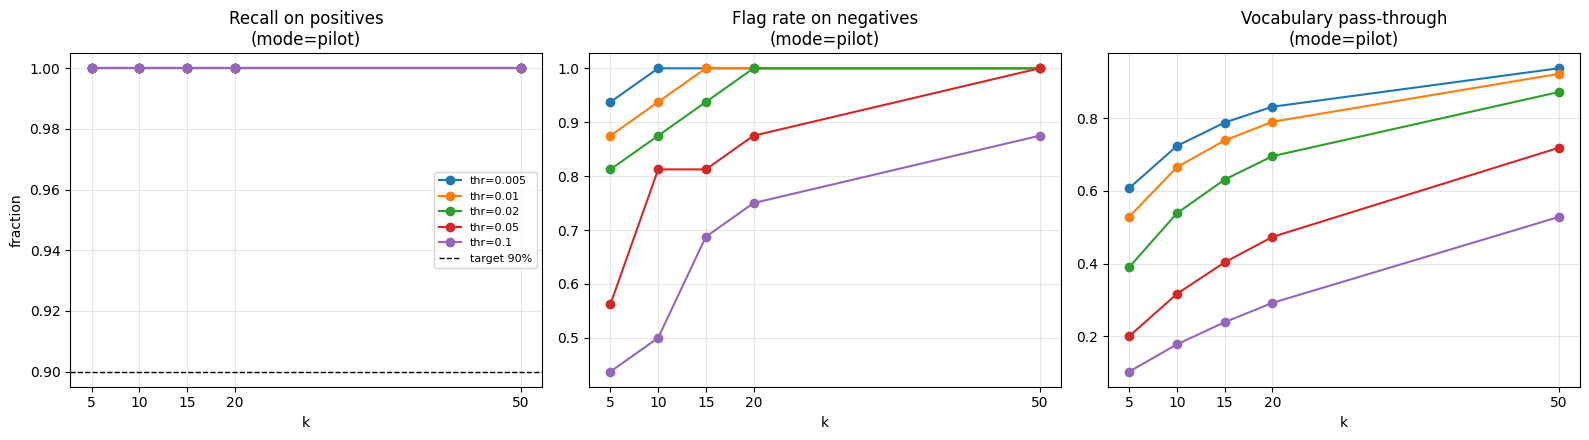

In [17]:
if HAVE_MPL:
    fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharex=True)
    panels = [
        ("recall", "Recall on positives", RECALL_TARGET),
        ("flag_rate_neg", "Flag rate on negatives", None),
        ("pass_through", "Vocabulary pass-through", None),
    ]
    for ax, (col, title, hline) in zip(axes, panels):
        for t in THRESHOLDS:
            sub = sweep[sweep["threshold"] == t].sort_values("k")
            ax.plot(sub["k"], sub[col], marker="o", label=f"thr={t}")
        if hline is not None:
            ax.axhline(hline, color="k", ls="--", lw=1,
                       label=f"target {hline:.0%}")
        ax.set_title(f"{title}\n(mode={mode})")
        ax.set_xlabel("k")
        ax.set_xticks(KS)
        ax.grid(True, alpha=0.3)
    axes[0].set_ylabel("fraction")
    axes[0].legend(fontsize=8)
    plt.tight_layout()
    plot_path = OUT_DIR / f"{STEM}_choose_k.png"
    try:
        fig.savefig(plot_path, dpi=150, bbox_inches="tight")
        print("Saved plot ->", plot_path)
    except Exception as e:  # noqa: BLE001
        print("Could not save plot:", e)
    plt.show()
else:
    print("matplotlib unavailable; see the tables above instead.")

## Recommendation

Rule (plan section 6, step 4): among `(k, threshold)` combinations whose
recall reaches `RECALL_TARGET`, pick the one with the **smallest `k`**, and
among ties the **lowest pass-through** (least work for the detector). If
nothing reaches the target, report the highest-recall combination and flag it.

Defaults from the plan if you prefer not to tune: `k=10` (lexical-substitution
convention), `k=20` (single compromise), `k=50` (recall-oriented).

In [18]:
reached = sweep[sweep["recall"] >= RECALL_TARGET].copy()

if len(reached):
    # Smallest k, then lowest pass-through, then highest threshold (tighter).
    reached = reached.sort_values(
        ["k", "pass_through", "threshold"],
        ascending=[True, True, False],
    )
    best = reached.iloc[0]
    print(f"RECOMMENDATION ({mode} mode):")
    print(f"  k = {int(best['k'])}, threshold = {best['threshold']}")
    print(f"  recall       = {best['recall']:.3f} (target {RECALL_TARGET:.0%})")
    print(f"  flag_rate_neg= {best['flag_rate_neg']:.3f}")
    print(f"  pass_through = {best['pass_through']:.3f} "
          f"({int(best['n_flagged'])}/{len(vocab_set)} words)")
else:
    best = sweep.sort_values(["recall", "k"], ascending=[False, True]).iloc[0]
    print(f"No (k, threshold) reached the {RECALL_TARGET:.0%} recall target.")
    print("Best available:")
    print(f"  k = {int(best['k'])}, threshold = {best['threshold']}, "
          f"recall = {best['recall']:.3f}")
    print("Consider: lowering the threshold, raising k (add 100 to KS and "
          "rerun the pipeline), or loosening MIN_CONTEXTS.")

if mode == "fallback":
    print("\nNOTE: fallback mode. flag_rate_neg == pass_through (no curated "
          "negatives). Treat the recommendation as provisional until "
          "pilot_words.json exists.")

RECOMMENDATION (pilot mode):
  k = 5, threshold = 0.1
  recall       = 1.000 (target 90%)
  flag_rate_neg= 0.438
  pass_through = 0.103 (1696/16489 words)


## Save the sweep

Write the full `(k, threshold)` sweep next to the summary so the choice is
reproducible and reviewable.

In [19]:
sweep_path = OUT_DIR / f"{STEM}_choose_k_sweep.csv"
out = sweep.copy()
out.insert(0, "mode", mode)
out.to_csv(sweep_path, index=False)
print("Saved sweep ->", sweep_path)
out

Saved sweep -> /storage/ice1/0/1/kli605/Emerging-and-New-Euphemism-Detection/masked_prediction/preprocessing/hits_drug_subreddits/hits_choose_k_sweep.csv


,mode,k,threshold,recall,flag_rate_neg,pass_through,n_flagged,n_pos_flagged,n_neg_flagged
0,pilot,5,0.005,1.0,0.9375,0.607799,10022,11,15
1,pilot,5,0.010,1.0,0.8750,0.529201,8726,11,14
2,pilot,5,0.020,1.0,0.8125,0.390442,6438,11,13
3,pilot,5,0.050,1.0,0.5625,0.200315,3303,11,9
4,pilot,5,0.100,1.0,0.4375,0.102856,1696,11,7
5,pilot,10,0.005,1.0,1.0000,0.723695,11933,11,16
6,pilot,10,0.010,1.0,0.9375,0.665171,10968,11,15
7,pilot,10,0.020,1.0,0.8750,0.538662,8882,11,14
8,pilot,10,0.050,1.0,0.8125,0.316817,5224,11,13
9,pilot,10,0.100,1.0,0.5000,0.177876,2933,11,8


## Per-positive diagnostics (which positives are missed?)

At the recommended `(k, threshold)`, list the positives that are NOT flagged.
These are the recall misses: either genuinely low-signal words, cells below
`MIN_CONTEXTS`, or (worth a manual look) list/tokenization issues.

In [20]:
best_k = int(best["k"])
best_t = float(best["threshold"])
flagged = flagged_words(summary, best_k, best_t, MIN_CONTEXTS)

missed = sorted(positives - flagged)
print(f"At k={best_k}, threshold={best_t}: {len(missed)} positive(s) missed "
      f"of {len(positives)}")

# Peak hit_rate_k over eligible half-years, to see how close each miss was.
elig = summary[summary["frequency"] >= MIN_CONTEXTS]
peak = (elig.groupby("word")[f"hit_rate_{best_k}"].max()
            .reindex(sorted(positives)))
diag = pd.DataFrame({"peak_hit_rate": peak})
diag["flagged"] = diag.index.isin(flagged)
diag.sort_values("peak_hit_rate", ascending=False)

At k=5, threshold=0.1: 0 positive(s) missed of 11


,peak_hit_rate,flagged
word,,
ecstasy,1.290598,True
fentanyl,0.926290,True
ketamine,0.924855,True
xanax,0.886272,True
adderall,0.805409,True
molly,0.672819,True
coke,0.642029,True
shrooms,0.604414,True
crack,0.547522,True
